# Number of Epochs: when to stop training

We reuse the plain MLP + Fashion-MNIST training loop (no convolutions) and look at one question: **how many epochs should we train for?**

An **epoch** is one full pass over the training data. Too few epochs and the model hasn't learned enough (*underfitting*). Too many and it starts memorizing the training set instead of learning general patterns (*overfitting*).

**Plan**
1. Split off a **validation set**, so we can judge the model without touching the test set
2. **Predict first**, then train for 40 epochs while recording everything
3. Read the curves: underfit, good fit, overfit, and why *loss* and *accuracy* tell different stories
4. Implement **early stopping** and restore the best weights
5. Bonus: how the amount of training data changes the answer

## 0. Setup

In [1]:
import math, time, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('PyTorch', torch.__version__, '| device:', device)

PyTorch 2.11.0+cu130 | device: cuda


## 1. Data: train / validation / test

If we pick the number of epochs by looking at the **test** set, then the test set is no longer an honest estimate of new data, because we tuned on it. The standard fix is three splits:

| Split | Size | Used for |
|---|---|---|
| train | 50,000 | updating the weights |
| **validation** | 10,000 | choosing hyperparameters, such as when to stop |
| test | 10,000 | one final, honest score at the very end |

In [2]:
mean, std = 0.2860, 0.3530
tr = datasets.FashionMNIST('data', train=True,  download=True)
te = datasets.FashionMNIST('data', train=False, download=True)

def to_tensors(ds):
    x = (ds.data.float() / 255 - mean) / std
    return x.unsqueeze(1), ds.targets

X_all, y_all = to_tensors(tr)
Xte, yte = to_tensors(te)

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(42))   # fixed split
tr_idx, va_idx = perm[:50000], perm[50000:]
Xtr, ytr = X_all[tr_idx], y_all[tr_idx]
Xva, yva = X_all[va_idx], y_all[va_idx]

val_loader  = DataLoader(TensorDataset(Xva, yva), batch_size=1000)
test_loader = DataLoader(TensorDataset(Xte, yte), batch_size=1000)
print('train', tuple(Xtr.shape), '| val', tuple(Xva.shape), '| test', tuple(Xte.shape))

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 204kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.79MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 14.8MB/s]


train (50000, 1, 28, 28) | val (10000, 1, 28, 28) | test (10000, 1, 28, 28)


## 2. Model and training function

Same plain MLP, a little wider than before (`784 -> 256 -> 128 -> 10`, ReLU) so that overfitting shows up within a reasonable number of epochs. SGD with lr 0.01 and momentum 0.9, batch size 64.

`run()` does the 5-step loop and, after **every epoch**, measures loss and accuracy on the full training set and the validation set (both in eval mode, so the curves are directly comparable). It also remembers the weights from the epoch with the lowest validation loss, and supports early stopping through `patience`.

In [3]:
class MLP(nn.Module):
    def __init__(self, hidden=(256, 128)):
        super().__init__()
        layers, d = [nn.Flatten()], 784
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]
            d = h
        layers.append(nn.Linear(d, 10))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

criterion = nn.CrossEntropyLoss()

def evaluate(model, loader):
    model.eval()
    total, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total += criterion(out, y).item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total / n, correct / n

def run(epochs, patience=None, lr=0.01, momentum=0.9, seed=0, hidden=(256, 128),
        subset=None, print_every=5, name=''):
    X, y = (Xtr, ytr) if subset is None else (Xtr[:subset], ytr[:subset])
    train_ds = TensorDataset(X, y)
    train_eval_loader = DataLoader(train_ds, batch_size=1000)
    g = torch.Generator().manual_seed(seed)
    loader = DataLoader(train_ds, batch_size=64, shuffle=True, generator=g)

    torch.manual_seed(seed)
    model = MLP(hidden).to(device)
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)

    h = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[])
    best_val, best_epoch, best_state, bad = float('inf'), 0, None, 0
    stopped_at = None

    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()                 # 1. clear gradients
            loss = criterion(model(xb), yb)       # 2-3. forward + loss
            loss.backward()                       # 4. backward
            optimizer.step()                      # 5. update

        trl, tra = evaluate(model, train_eval_loader)
        val, vaa = evaluate(model, val_loader)
        for k, v in zip(['train_loss', 'train_acc', 'val_loss', 'val_acc'], [trl, tra, val, vaa]):
            h[k].append(v)

        if val < best_val - 1e-4:                 # new best validation loss: remember these weights
            best_val, best_epoch, bad = val, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1

        if print_every and (epoch == 1 or epoch % print_every == 0):
            print(f'  {name} epoch {epoch:3d}  train_loss={trl:.4f} val_loss={val:.4f}  train_acc={tra:.4f} val_acc={vaa:.4f}')
        if patience is not None and bad >= patience:     # early stopping
            stopped_at = epoch
            print(f'  {name} early stop at epoch {epoch} (no val-loss improvement for {patience} epochs); best epoch = {best_epoch}')
            break

    return dict(hist=h, model=model, best_state=best_state, best_epoch=best_epoch, stopped_at=stopped_at, hidden=hidden)

## 3. Predict first

You are about to train for **40 epochs**. Before running, guess (on paper or in the chat):

| Question | Your guess |
|---|---|
| Validation accuracy after 1 epoch | |
| Validation accuracy after 10 epochs | |
| Validation accuracy after 40 epochs | |
| Training accuracy after 40 epochs | |
| Will **validation loss** keep falling for all 40 epochs? If not, around which epoch does it bottom out? | |
| Will **validation accuracy** keep rising for all 40 epochs? | |

## 4. Train for 40 epochs and record everything

In [4]:
EPOCHS = 40
t0 = time.time()
main = run(EPOCHS, name='40ep')
print(f'done in {time.time()-t0:.0f}s | best validation-loss epoch: {main["best_epoch"]}')

  40ep epoch   1  train_loss=0.4092 val_loss=0.4351  train_acc=0.8524 val_acc=0.8421
  40ep epoch   5  train_loss=0.2610 val_loss=0.3206  train_acc=0.9034 val_acc=0.8823
  40ep epoch  10  train_loss=0.1949 val_loss=0.3172  train_acc=0.9273 val_acc=0.8896
  40ep epoch  15  train_loss=0.1353 val_loss=0.3196  train_acc=0.9492 val_acc=0.8982
  40ep epoch  20  train_loss=0.1169 val_loss=0.3664  train_acc=0.9548 val_acc=0.8883
  40ep epoch  25  train_loss=0.1033 val_loss=0.4201  train_acc=0.9610 val_acc=0.8882
  40ep epoch  30  train_loss=0.0698 val_loss=0.4381  train_acc=0.9746 val_acc=0.8971
  40ep epoch  35  train_loss=0.0657 val_loss=0.5087  train_acc=0.9751 val_acc=0.8892
  40ep epoch  40  train_loss=0.0496 val_loss=0.5358  train_acc=0.9817 val_acc=0.8969
done in 79s | best validation-loss epoch: 7


### 4a. The curves

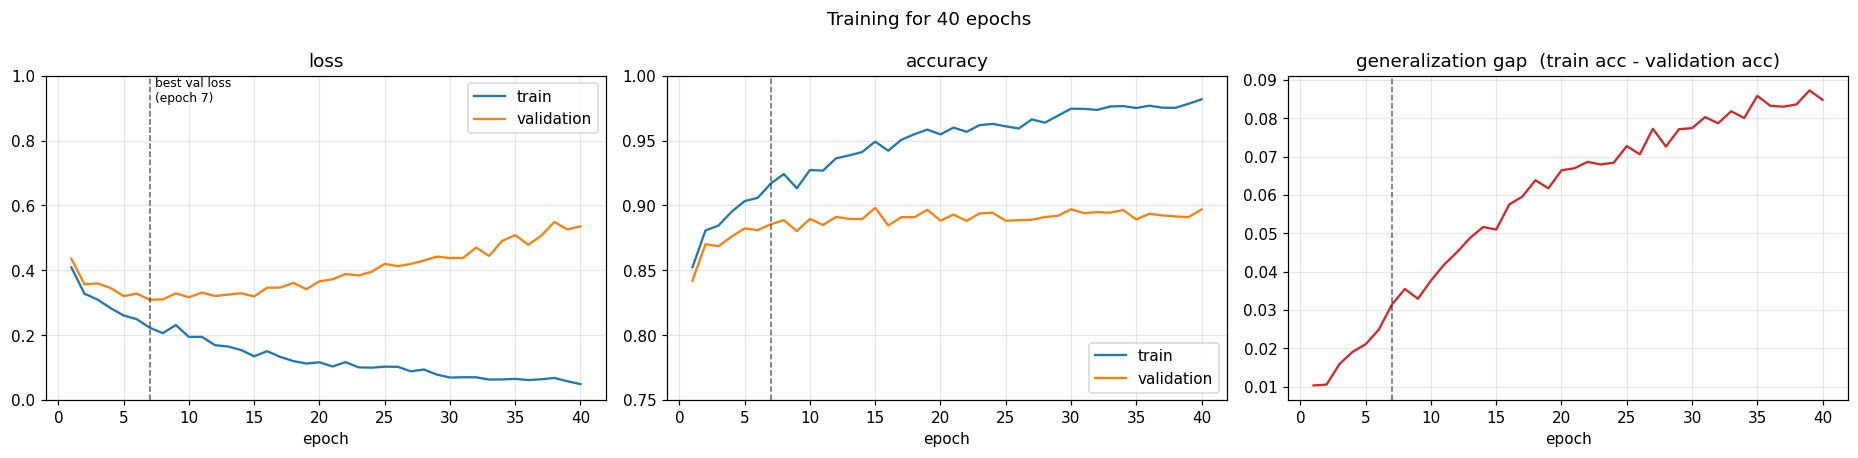

In [5]:
def plot_run(r, title=''):
    h, be = r['hist'], r['best_epoch']
    e = np.arange(1, len(h['train_loss']) + 1)
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    ax[0].plot(e, h['train_loss'], label='train'); ax[0].plot(e, h['val_loss'], label='validation')
    ax[0].set_title('loss'); ax[0].set_ylim(0, max(1.0, min(2.0, max(h['val_loss']) * 1.05)))
    ax[1].plot(e, h['train_acc'], label='train'); ax[1].plot(e, h['val_acc'], label='validation')
    ax[1].set_title('accuracy'); ax[1].set_ylim(0.75, 1.0)
    ax[2].plot(e, np.array(h['train_acc']) - np.array(h['val_acc']), color='C3')
    ax[2].set_title('generalization gap  (train acc - validation acc)')
    for a in ax:
        a.axvline(be, color='k', ls='--', lw=1, alpha=.6); a.set_xlabel('epoch')
    ax[0].text(be + .4, ax[0].get_ylim()[1] * .92, f'best val loss\n(epoch {be})', fontsize=8)
    ax[0].legend(); ax[1].legend(); fig.suptitle(title); plt.tight_layout(); plt.show()

plot_run(main, 'Training for 40 epochs')

### 4b. What if we had stopped at epoch N?

In [6]:
h = main['hist']
snap = [1, 2, 3, 5, 10, 15, 20, 30, 40]
rows = []
for n in snap:
    i = n - 1
    rows.append({'stop after epoch': n, 'train_loss': h['train_loss'][i], 'val_loss': h['val_loss'][i],
                 'train_acc': h['train_acc'][i], 'val_acc': h['val_acc'][i],
                 'gap (acc)': h['train_acc'][i] - h['val_acc'][i]})
display(pd.DataFrame(rows).set_index('stop after epoch').round(4))

,train_loss,val_loss,train_acc,val_acc,gap (acc)
stop after epoch,,,,,
1,0.4092,0.4351,0.8524,0.8421,0.0103
2,0.3281,0.3571,0.8808,0.8702,0.0106
3,0.3102,0.3598,0.8846,0.8686,0.0160
5,0.2610,0.3206,0.9034,0.8823,0.0211
10,0.1949,0.3172,0.9273,0.8896,0.0377
15,0.1353,0.3196,0.9492,0.8982,0.0510
20,0.1169,0.3664,0.9548,0.8883,0.0665
30,0.0698,0.4381,0.9746,0.8971,0.0775
40,0.0496,0.5358,0.9817,0.8969,0.0848


Since the learning rate is constant, the model at epoch N is exactly what you would have after training for N epochs and stopping, so a single long run tells us about *every* shorter run.

## 5. Reading the curves

The three regimes (the dashed line marks the epoch with the lowest validation loss):

- **Left of the line, underfitting:** both train and validation loss are falling, and both accuracies are rising. The model hasn't learned all it can. More epochs help.
- **Around the line, good fit:** validation loss bottoms out. The train and validation curves are still close.
- **Right of the line, overfitting:** train loss keeps falling, but validation loss turns **up**, and the gap between train and validation accuracy keeps growing. The model is memorizing training examples.

Notice that validation **accuracy** typically stays almost flat (or drifts slightly) while validation **loss** climbs. Next, we find out why.

## 6. Why can loss rise while accuracy stays flat?

Cross-entropy punishes a wrong prediction according to how *confident* it was. As training continues, the network becomes more and more confident, including on the examples it gets wrong. A few confidently-wrong predictions add a lot of loss, while accuracy (just right/wrong) barely changes.

Compare the model at the **best epoch** with the model at the **last epoch** on the validation set:

In [7]:
def confidence_stats(model, loader):
    model.eval()
    conf, correct = [], []
    with torch.no_grad():
        for x, y in loader:
            p = torch.softmax(model(x.to(device)), dim=1)
            c, pred = p.max(dim=1)
            conf.append(c.cpu()); correct.append((pred.cpu() == y))
    conf, correct = torch.cat(conf), torch.cat(correct)
    return dict(acc=correct.float().mean().item(),
                mean_conf_when_right=conf[correct].mean().item(),
                mean_conf_when_WRONG=conf[~correct].mean().item(),
                share_wrong_with_conf_over_90pct=((conf > 0.9) & ~correct).float().sum().item() / (~correct).sum().item())

best_model = MLP(main['hidden']).to(device)
best_model.load_state_dict(main['best_state'])

stats = pd.DataFrame({f'best epoch ({main["best_epoch"]})': confidence_stats(best_model, val_loader),
                      f'last epoch ({EPOCHS})':            confidence_stats(main['model'], val_loader)}).T
display(stats.round(4))

,acc,mean_conf_when_right,mean_conf_when_WRONG,share_wrong_with_conf_over_90pct
best epoch (7),0.8855,0.9326,0.6571,0.1362
last epoch (40),0.8969,0.9790,0.8452,0.5179


Accuracy is similar for both models, but the later model is typically **more confident when it is wrong**, which is what pushes the loss up. This is overconfidence, a form of overfitting that accuracy alone does not reveal. It is also why we watch the validation **loss**, not only the accuracy.

## 7. Early stopping

Instead of guessing the number of epochs, let the validation set decide:

1. After every epoch, check the validation loss.
2. If it hasn't improved for `patience` epochs in a row, stop.
3. Go back to the weights from the best epoch.

`run()` already contains this logic (`patience=...`, plus `best_state`). Train again with `patience=5`:

In [8]:
es = run(EPOCHS, patience=5, name='early-stop')

  early-stop epoch   1  train_loss=0.4092 val_loss=0.4351  train_acc=0.8524 val_acc=0.8421
  early-stop epoch   5  train_loss=0.2610 val_loss=0.3206  train_acc=0.9034 val_acc=0.8823
  early-stop epoch  10  train_loss=0.1949 val_loss=0.3172  train_acc=0.9273 val_acc=0.8896
  early-stop early stop at epoch 12 (no val-loss improvement for 5 epochs); best epoch = 7


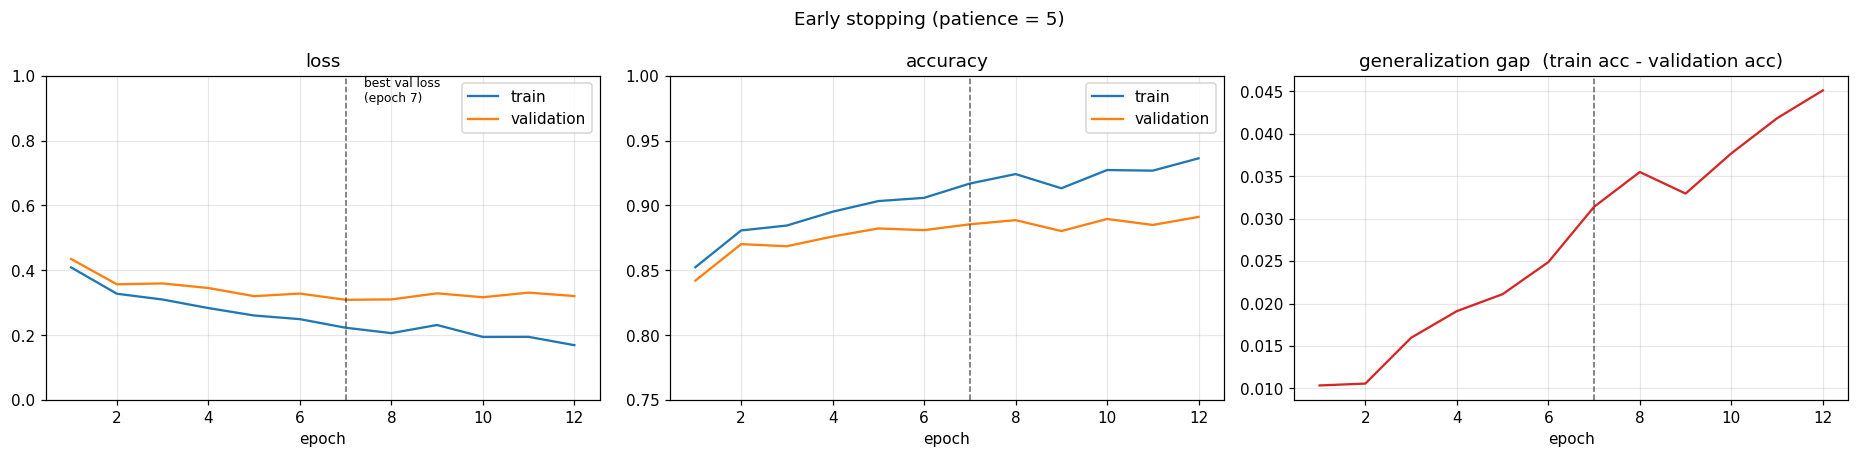

In [9]:
plot_run(es, 'Early stopping (patience = 5)')

### 7a. The final, honest comparison on the test set

Now, and only now, use the test set. Three candidates:
1. the model after **all 40 epochs** (no stopping)
2. the **best-validation-loss** weights from the 40-epoch run
3. the model from **early stopping** (best weights restored)

In [10]:
def test_score(model, state=None):
    if state is not None:
        m = MLP(main['hidden']).to(device); m.load_state_dict(state); model = m
    return evaluate(model, test_loader)

rows = []
for name, (loss, acc), epochs_used in [
    ('last epoch of 40-epoch run',       test_score(main['model']),                  EPOCHS),
    ('best-val-loss epoch (40-ep run)',  test_score(None, main['best_state']),       EPOCHS),
    ('early stopping, patience 5',       test_score(None, es['best_state']),         es['stopped_at'] or EPOCHS),
]:
    rows.append({'model': name, 'epochs trained': epochs_used, 'test_loss': loss, 'test_acc': acc})
display(pd.DataFrame(rows).set_index('model').round(4))

,epochs trained,test_loss,test_acc
model,,,
last epoch of 40-epoch run,40,0.5872,0.8888
best-val-loss epoch (40-ep run),40,0.3360,0.8798
"early stopping, patience 5",12,0.3360,0.8798


Typically: the early-stopped model gets a clearly **lower test loss** than the 40-epoch model, with a similar or slightly better test accuracy, and it trains in a fraction of the time. The second and third rows should match closely, because early stopping picks the same best epoch (small differences can come from GPU non-determinism).

## 8. Bonus: the right number of epochs depends on how much data you have

With less data, a network can memorize the training set much sooner. Repeat the experiment on only the first **2,000** training images (the same 10,000 validation images).

best validation-loss epoch: full data = 7 | 2,000 images = 13


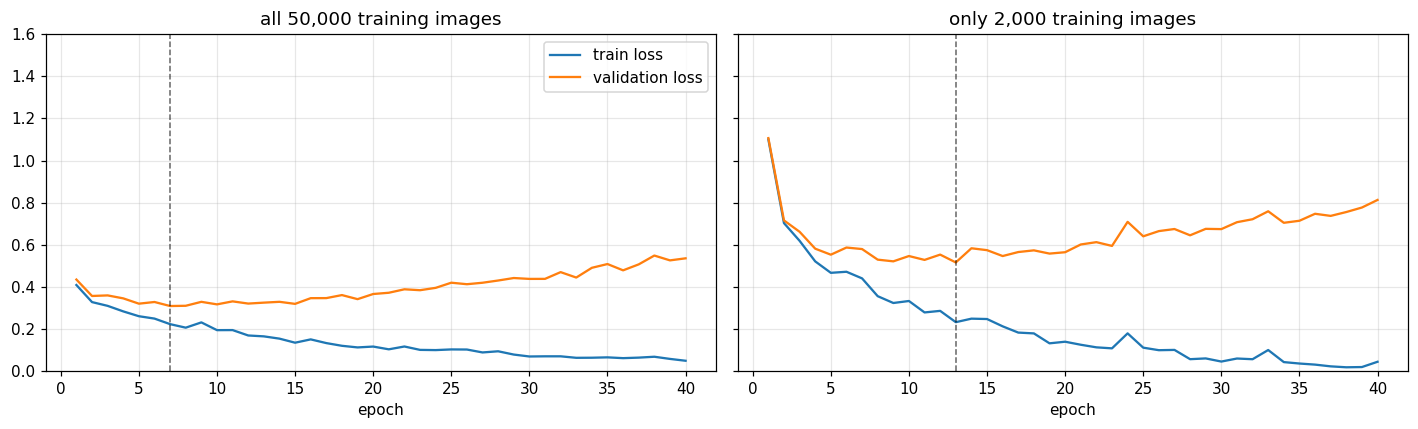

final train acc: 2k = 0.986, full = 0.982
final val   acc: 2k = 0.817, full = 0.897


In [11]:
small = run(EPOCHS, subset=2000, print_every=0, name='2k')
print('best validation-loss epoch: full data =', main['best_epoch'], '| 2,000 images =', small['best_epoch'])

fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, r, title in [(ax[0], main, 'all 50,000 training images'), (ax[1], small, 'only 2,000 training images')]:
    h = r['hist']; e = np.arange(1, len(h['train_loss']) + 1)
    a.plot(e, h['train_loss'], label='train loss'); a.plot(e, h['val_loss'], label='validation loss')
    a.axvline(r['best_epoch'], color='k', ls='--', lw=1, alpha=.6)
    a.set_title(title); a.set_xlabel('epoch'); a.set_ylim(0, 1.6)
ax[0].legend(); plt.tight_layout(); plt.show()

hs, hm = small['hist'], main['hist']
print(f"final train acc: 2k = {hs['train_acc'][-1]:.3f}, full = {hm['train_acc'][-1]:.3f}")
print(f"final val   acc: 2k = {hs['val_acc'][-1]:.3f}, full = {hm['val_acc'][-1]:.3f}")

With 2,000 images the model reaches near-perfect training accuracy while validation accuracy stays far lower, and the validation loss typically bottoms out within the first few epochs and then climbs steeply. **Less data, or a bigger model, means overfitting starts earlier.** There is no universal "right" number of epochs: let the validation curve tell you.

## Takeaways

1. **Too few epochs:** underfit. Both train and validation are still improving.
2. **Too many epochs:** overfit. Training keeps improving, but validation loss turns up and the train/validation gap widens.
3. **Watch validation loss**, not just accuracy: loss reveals growing overconfidence before accuracy moves.
4. **Never choose epochs using the test set.** Use a validation set, and touch the test set once at the end.
5. **Early stopping** (patience + restore the best weights) finds the right number of epochs automatically, and saves compute.
6. The best epoch depends on the data size, the model size, and the learning rate. Always check the curves.

## Exercises
1. Change `patience` to 1, 5 and 15. What is the trade-off?
2. Increase the model size (`hidden=(1024, 512)`). Does the best epoch move earlier or later?
3. Lower the learning rate to 0.001 and train for 100 epochs. How does the best epoch change?
4. Add `nn.Dropout(0.3)` after each ReLU (and call `model.train()` / `model.eval()` correctly). Does overfitting start later?
5. Add `weight_decay=1e-3` to the optimizer. Same question.
6. Use `Adam(lr=1e-3)` instead of SGD. How early is the best epoch now?
7. Save the best weights to disk with `torch.save(best_state, 'best.pt')` after early stopping, and load them in a new session.